# Tarea 02 - Reconocimiento de Patrones en Imágenes
**Laura Romero**

---

## Instrucciones de uso
1. Colocar la imagen `rice.png` en la misma carpeta que este notebook.
2. Ejecutar las celdas en orden de arriba hacia abajo.
3. Al final se muestra una tabla con las características extraídas para cada grano de arroz:
   - **(1) Color promedio** de cada grano (en escala de grises)
   - **(2) Gradiente promedio** del contorno de cada grano
   - **(3) Contraste** región vs entorno de cada grano
   - **(4) Momentos de Hu** (φ1 a φ7) calculados en escala de grises


---

## Paso 1: Importar librerías y cargar la imagen
Primero importamos las librerías que vamos a usar y leemos la imagen en escala de grises.
Usamos `cv2.imread` con el parámetro `0` para leerla directamente en grises.

Tamaño de la imagen: (830, 830)
Valor minimo: 0 Valor maximo: 216


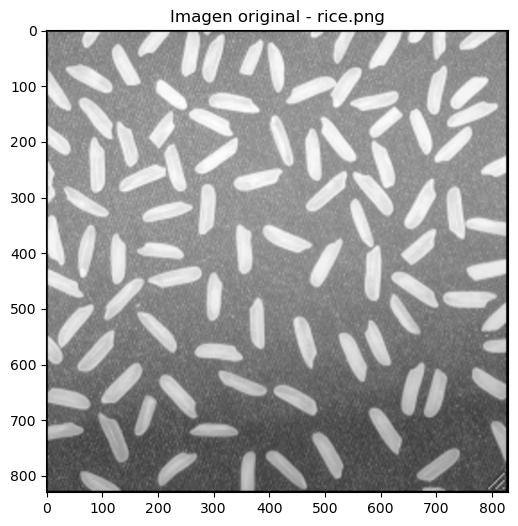

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt
import pandas as pd

# leemos la imagen en escala de grises (parametro 0)
img = cv2.imread('rice.png', 0)

print("Tamaño de la imagen:", img.shape)
print("Valor minimo:", img.min(), "Valor maximo:", img.max())

plt.figure(figsize=(6,6))
plt.imshow(img, cmap='gray')
plt.title('Imagen original - rice.png')
plt.show()

## Paso 2: Corregir iluminación y binarizar

La imagen tiene iluminación no uniforme (unas zonas son más claras que otras), lo que dificulta la binarización directa. Para arreglar esto, se estimó el fondo con un blur gaussiano grande y se le restó a la imagen original. Así la iluminación queda más pareja y todos los granos se separan mejor del fondo.

Después se binarizó la imagen corregida con un umbral de 150 usando cv2.threshold.

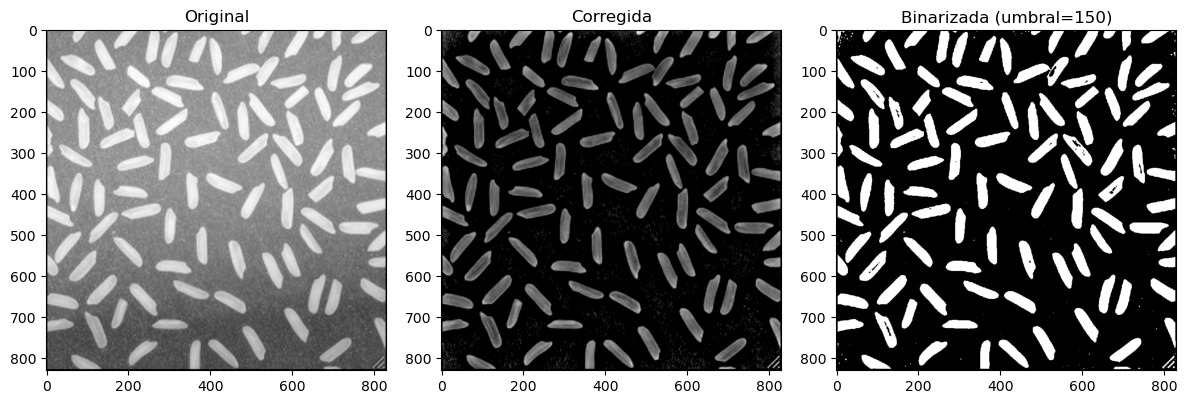

In [11]:
# estimamos el fondo con un blur gaussiano grande
fondo = cv2.GaussianBlur(img, (101, 101), 0)

# restamos el fondo para corregir la iluminacion
corregida = cv2.subtract(img, fondo) + 128

# binarizamos la imagen corregida con umbral 150
th, bw = cv2.threshold(corregida, 150, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.subplot(1,3,2)
plt.imshow(corregida, cmap='gray')
plt.title('Corregida')
plt.subplot(1,3,3)
plt.imshow(bw, cmap='gray')
plt.title('Binarizada (umbral=150)')
plt.tight_layout()
plt.show()

## Paso 3: Encontrar los contornos de cada grano
Usamos `cv2.findContours` para extraer el perímetro de cada grano de arroz.
Filtramos los contornos muy pequeños y también los que tocan el borde de la imagen y son muy chicos.

Granos de arroz detectados: 97


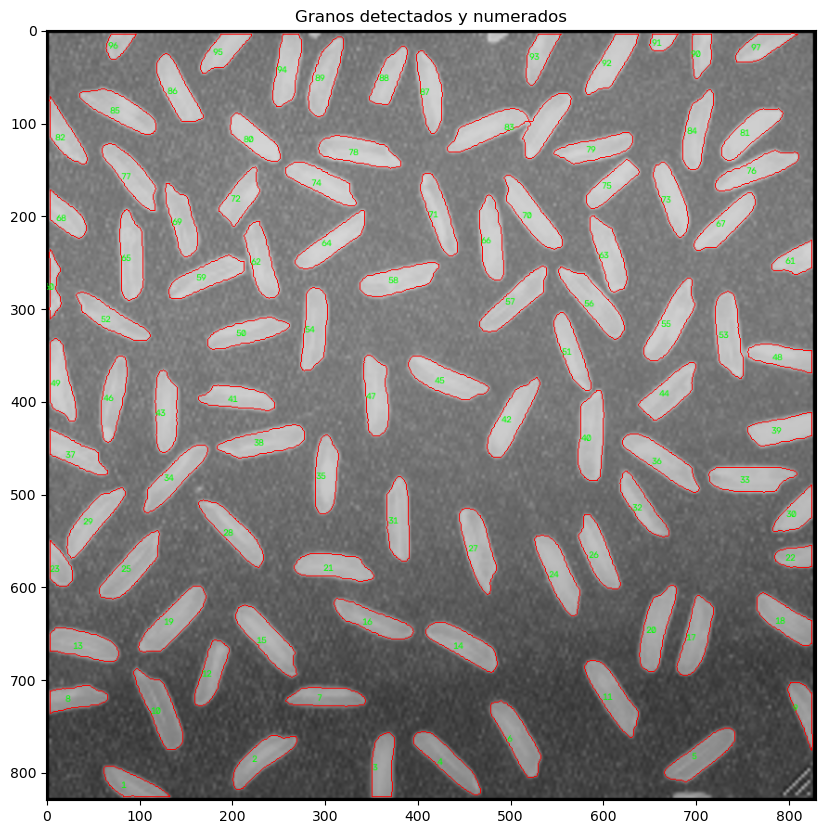

In [12]:
# extraemos los contornos de cada grano
contornos, hc = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

# filtramos contornos muy chicos (ruido)
contornos = [c for c in contornos if cv2.contourArea(c) > 200]

# funcion para saber si un contorno toca el borde de la imagen
def toca_borde(contorno, filas, columnas, margen=3):
    x, y, w, h = cv2.boundingRect(contorno)
    if x <= margen or y <= margen:
        return True
    if (x + w) >= columnas - margen or (y + h) >= filas - margen:
        return True
    return False

# tratamiento de granos en el borde:
# los que tocan el borde y son muy chicos (area < 500) son artefactos, los eliminamos
# los que tocan el borde pero son mas grandes los mantenemos porque son granos reales (cortados o no)
filas, columnas = img.shape
contornos = [c for c in contornos if not (toca_borde(c, filas, columnas) and cv2.contourArea(c) < 500)]

print("Granos de arroz detectados:", len(contornos))

# dibujamos los contornos y el numero de cada grano para poder ubicarlos
img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
cv2.drawContours(img_color, contornos, -1, (255,0,0), 1)

for idx, c in enumerate(contornos):
    M = cv2.moments(c)
    if M["m00"] != 0:
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
        cv2.putText(img_color, str(idx+1), (cx-10, cy+5), cv2.FONT_HERSHEY_SIMPLEX, 0.35, (0,255,0), 1)

plt.figure(figsize=(10,10))
plt.imshow(img_color)
plt.title('Granos detectados y numerados')
plt.show()

## Paso 4: Definir las funciones para extraer características
Ahora definimos las 4 funciones que calculan cada descriptor.

### 4.1 Color promedio
Es simplemente el promedio de los valores de gris dentro de la región del grano.
En el ramo vimos `np.mean(canal)` para calcular el promedio de un canal.
Acá usamos una máscara para tomar solo los píxeles que pertenecen al grano.

In [13]:
def color_promedio(img_gray, contorno):
    # creamos una mascara negra del tamaño de la imagen
    mascara = np.zeros(img_gray.shape, dtype='uint8')
    # rellenamos la region del grano con blanco
    cv2.drawContours(mascara, [contorno], -1, 255, -1)
    # sacamos el promedio solo de los pixeles dentro de la mascara
    promedio = cv2.mean(img_gray, mask=mascara)[0]
    return promedio

### 4.2 Gradiente promedio
Recorremos los píxeles del contorno y calculamos el gradiente en cada punto.
En clases se definió la función `gradiente`:
- Lx = -0.5 * L[i-1,j] + 0.5 * L[i+1,j]
- Ly = -0.5 * L[i,j-1] + 0.5 * L[i,j+1]
- magnitud = sqrt(Lx² + Ly²)

Y al final se promedia la magnitud sobre todos los puntos del contorno.

In [14]:
def gradiente_promedio(img_gray, contorno):
    # misma logica que la funcion gradiente() 
    # recorremos cada punto del contorno y calculamos Lx y Ly
    pos = np.vstack(contorno)
    filas, columnas = img_gray.shape
    mag = 0
    N = 0
    
    for punto in pos:
        j, i = punto[0], punto[1]
        
        # nos aseguramos de no salirnos de los bordes de la imagen
        if i > 0 and i < filas-1 and j > 0 and j < columnas-1:
            # derivada en x: diferencia centrada
            lx = -0.5 * float(img_gray[i-1, j]) + 0.5 * float(img_gray[i+1, j])
            # derivada en y: diferencia centrada
            ly = -0.5 * float(img_gray[i, j-1]) + 0.5 * float(img_gray[i, j+1])
            # magnitud del gradiente
            mag += sqrt(lx**2 + ly**2)
            N += 1
    
    if N == 0:
        return 0
    
    promedio = mag / N
    return promedio

### 4.3 Contraste (región vs entorno)
Para calcular el contraste de cada grano, comparamos la intensidad media del grano (G) con la intensidad media de su entorno (C).
El entorno lo definimos como un anillo alrededor del grano: dilatamos la máscara del grano y le restamos la máscara original, así obtenemos solo los píxeles que rodean al grano sin incluirlo.
Usamos la fórmula de contraste: **(G - C) / (G + C)**

In [15]:
def contraste_region_entorno(img_gray, contorno):
    # mascara del grano (region interior)
    mascara_grano = np.zeros(img_gray.shape, dtype='uint8')
    cv2.drawContours(mascara_grano, [contorno], -1, 255, -1)
    
    # dilatamos la mascara para obtener el grano + su entorno
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    mascara_dilatada = cv2.dilate(mascara_grano, kernel)
    
    # el entorno es la dilatada menos el grano original (anillo)
    mascara_entorno = cv2.subtract(mascara_dilatada, mascara_grano)
    
    # intensidad media del grano (G)
    G = cv2.mean(img_gray, mask=mascara_grano)[0]
    
    # intensidad media del entorno (C)
    C = cv2.mean(img_gray, mask=mascara_entorno)[0]
    
    # formula de contraste
    if (G + C) == 0:
        return 0
    contraste = (G - C) / (G + C)
    return contraste

### 4.4 Momentos de Hu (φ1 a φ7) en escala de grises
Los momentos de Hu son 7 valores invariantes a traslación, rotación y escala.
Para calcularlos en escala de grises usamos `cv2.moments` sobre la imagen original enmascarada con la región del grano.
Después con `cv2.HuMoments` obtenemos los 7 momentos.
Les aplicamos escala logarítmica para que los valores sean más manejables.

In [16]:
def momentos_hu(img_gray, contorno):
    # creamos mascara del grano
    mascara = np.zeros(img_gray.shape, dtype='uint8')
    cv2.drawContours(mascara, [contorno], -1, 255, -1)
    
    # calculamos los momentos sobre la imagen en escala de grises (no la binaria)
    momentos = cv2.moments(img_gray, binaryImage=False)
    
    # pero necesitamos los momentos SOLO del grano, no de toda la imagen
    # entonces enmascaramos: ponemos en 0 todo lo que no es el grano
    img_masked = cv2.bitwise_and(img_gray, img_gray, mask=mascara)
    momentos = cv2.moments(img_masked, binaryImage=False)
    
    # obtenemos los 7 momentos de Hu
    hu = cv2.HuMoments(momentos).flatten()
    
    # aplicamos log para que los valores sean mas faciles de leer
    # usamos -sign * log10(|hu|) para mantener el signo
    hu_log = []
    for h in hu:
        if h != 0:
            hu_log.append(-np.sign(h) * np.log10(abs(h)))
        else:
            hu_log.append(0)
    
    return hu_log

## Paso 5: Extraer las características para cada grano
Recorremos cada grano de arroz detectado y calculamos los descriptores:
color promedio, gradiente promedio, contraste y los 7 momentos de Hu.

In [17]:
# lista donde guardamos los resultados de cada grano
resultados = []

for idx, contorno in enumerate(contornos):
    # (1) Color promedio
    color = color_promedio(img, contorno)
    
    # (2) Gradiente promedio del perimetro
    grad = gradiente_promedio(img, contorno)
    
    # (3) Contraste region vs entorno
    contr = contraste_region_entorno(img, contorno)
    
    # (4) Momentos de Hu (7 valores) en escala de grises
    hu = momentos_hu(img, contorno)
    
    fila = [idx+1, color, grad, contr] + hu
    resultados.append(fila)

print("Caracteristicas extraidas para", len(resultados), "granos")

Caracteristicas extraidas para 97 granos


## Paso 6: Mostrar la tabla de resultados
Armamos un DataFrame de pandas para que se vea ordenado.

In [18]:
# armamos la tabla con pandas
columnas = ['Grano', 'Color Promedio', 'Gradiente Promedio', 'Contraste',
            'φ1', 'φ2', 'φ3', 'φ4', 'φ5', 'φ6', 'φ7']
df = pd.DataFrame(resultados, columns=columnas)
df = df.set_index('Grano')

# mostramos la tabla completa
print("TABLA DE CARACTERISTICAS POR GRANO DE ARROZ")
print("(Momentos de Hu en escala logaritmica)")
print("")
print(df.to_string())
print("")
print("Total de granos:", len(df))

TABLA DE CARACTERISTICAS POR GRANO DE ARROZ
(Momentos de Hu en escala logaritmica)

       Color Promedio  Gradiente Promedio  Contraste        φ1        φ2         φ3         φ4         φ5         φ6         φ7
Grano                                                                                                                          
1          146.543091           16.187883   0.346875  2.735523  5.679367   9.082189   9.623710  19.003630  12.593082  19.442939
2          151.934372           16.590637   0.295687  2.729873  5.640533   9.283683  10.242061 -20.349008 -13.258046  20.054762
3          153.567586           16.192805   0.328436  2.752268  5.691308  10.128394  10.908398  21.957323  15.296297 -21.446531
4          142.863441           16.586234   0.317673  2.611830  5.324921   9.574740   9.856884  19.577252  12.558461 -20.414056
5          141.183275           15.959282   0.285329  2.686638  5.533301   9.995105  10.887029  22.219762 -14.444471  21.331701
6          150.04347